<a href="https://colab.research.google.com/github/olyadiya/DL_2026/blob/main/hf_transformers_hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Text classification task guide**

1. Что делает данный компонент/функция: присваивает лейбл или класс тектсу.

2. Какие параметры критичны для классификации текста и почему
* num_labels, id2label, label2id: определяют размер
классификатора и читаемые названия классов в предсказаниях.
* truncation=True (и max_length): снижают размер текстов, так как без обрезки длинные тексты вызовут ошибку или превысят лимит модели.

3. Один пример кода из туториала, который вы планируете использовать.

# **Trainer**

1. Что делает данный компонент/функция: предоставляет API для полноценного обучения в PyTorch и поддерживает распределённое обучение на нескольких GPU/TPU, смешанную точность для NVIDIA (лол) GPU, AMD GPU, а также torch.amp для PyTorch.

2. Какие параметры критичны для классификации текста и почему.
* learning_rate, num_train_epochs, per_device_train_batch_size: основные гиперпараметры для дообучения.
* eval_strategy="epoch" и save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro": нужны, чтобы в конце загрузилась лучшая, а не последняя модель.
* EarlyStoppingCallback: останавливает обучение, если метрика не улучшалась 2 оценки подряд, защищая от переобучения.

3. Один пример кода из туториала, который вы планируете использовать.

# **Datasets: load local CSV/JSON**

1. Что делает данный компонент/функция: загружает датасет.

2. Какие параметры критичны для классификации текста и почему.
* train_test_split: если готового validation нет, стратификация сохраняет пропорции классов, что важно при дисбалансе.
* data_files={"train": ..., "validation": ...}: задаёт готовые сплиты.

3. Один пример кода из туториала, который вы планируете использовать.


# **Evaluate: F1 metric**
1. Что делает данный компонент/функция: предоставляет готовые метрики (accuracy, f1, precision, recall) и метод compute. F1 - среднее precision и recall, а способ усреднения по классам задаётся параметром average.

2. Какие параметры критичны для классификации текста и почему.
* average="macro": считает F1 для каждого класса и берёт простое среднее, чтобы вес классы весили одинаково.
* average="micro": суммирует TP/FP/FN по всем классам.
* average="weighted": среднее с весами по числу примеров класса.

3. Один пример кода из туториала, который вы планируете использовать.


**1. Чем single_label_classification отличается от multi_label_classification с точки зрения функции потерь?**

* single_label_classification (один класс из N): модель выдаёт логиты для N классов, к ним применяется softmax, а функция потерь — CrossEntropyLoss. У взаимоисключающихся классов вероятности суммируются в 1, и рост вероятности одного класса снижает остальные. Метка — одно целое число (индекс класса).
* multi_label_classification (несколько классов одновременно): к каждому логиту независимо применяется sigmoid, а функция потерь — BCEWithLogitsLoss. Метка — вектор из 0/1 длиной N (в float).

**2. Зачем нужен processing_class=tok в Trainer (а не tokenizer=tok)?**
* Параметр tokenizer в Trainer устарел (deprecated) и в новых версиях Transformers заменён на processing_class. Trainer теперь работает не только с текстовыми моделями, но и с мультимодальными, где обработчик входов — это не токенизатор, а Processor (ImageProcessor, FeatureExtractor, AutoProcessor).

**3. Что произойдёт, если не передать compute_metrics в Trainer?**
* Обучение и оценка запустятся без ошибок, но в результатах evaluate и логах будет только eval_loss; accuracy, F1 и другие метрики посчитаны не будут;
* Trainer не найдёт метрики и выдаст ошибку при выборе лучшей модели.


# **Часть 2. Выбор темы и обучение классификатора**

In [1]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib pandas

import torch
import numpy as np
import pandas as pd
import evaluate
import matplotlib.pyplot as plt
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print(f"Transformers version: {__import__('transformers').__version__}")
print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Transformers version: 5.22.1
Device: cuda


In [2]:
raw = load_dataset("stanfordnlp/imdb")
print(raw)

#в imdb нет validation: выделяем 10% train, сохраняя пропорции классов
split = raw["train"].train_test_split(test_size=0.1, seed=42, stratify_by_column="label")
datasets = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": raw["test"],
})

label_names = raw["train"].features["label"].names
num_labels = len(label_names)
id2label = {i: n for i, n in enumerate(label_names)}
label2id = {n: i for i, n in id2label.items()}

print("\nПример записи:", datasets["train"][0]["text"][:200], "...")
for name, ds in datasets.items():
    counts = np.bincount(ds["label"], minlength=num_labels)
    print(f"{name:10s} размер={len(ds):6d} | распределение классов: {dict(zip(label_names, counts))}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Пример записи: Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this ...
train      размер= 22500 | распределение классов: {'neg': np.int64(11250), 'pos': np.int64(11250)}
validation размер=  2500 | распределение классов: {'neg': np.int64(1250), 'pos': np.int64(1250)}
test       размер= 25000 | распределение классов: {'neg': np.int64(12500), 'pos': np.int64(12500)}


In [3]:
checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize_function(example):
    return tokenizer(
        example["text"],
        truncation=True,
        max_length=256,
    )

tokenized = datasets.map(tokenize_function, batched=True)
print("Ключи после токенизации:", list(tokenized["train"][0].keys()))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/22500 [00:00<?, ? examples/s]

Map:   0%|          | 0/2500 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Ключи после токенизации: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask']


In [4]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    acc = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    f1_macro = f1_metric.compute(
        predictions=predictions, references=labels, average="macro"
    )["f1"]
    return {"accuracy": acc, "f1_macro": f1_macro}

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

training_args = TrainingArguments(
    output_dir="./imdb-output",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
train_result = trainer.train()
print(f"Train loss: {train_result.training_loss:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.262133,0.238081,0.903600,0.903560
2,0.179926,0.284324,0.910800,0.910754
3,0.105405,0.355133,0.907200,0.907160
4,0.051898,0.423898,0.908400,0.908399


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Train loss: 0.1599


In [7]:
val_res = trainer.evaluate(tokenized["validation"])
test_res = trainer.evaluate(tokenized["test"])

results_table = pd.DataFrame(
    {
        "validation": [val_res["eval_accuracy"], val_res["eval_f1_macro"], val_res["eval_loss"]],
        "test":       [test_res["eval_accuracy"], test_res["eval_f1_macro"], test_res["eval_loss"]],
    },
    index=["eval_accuracy", "eval_f1_macro", "eval_loss"],
).round(4)
display(results_table)

gap = test_res["eval_accuracy"] - test_res["eval_f1_macro"]
print(f"Разрыв accuracy - f1_macro на test: {gap:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.051898,0.284324,4,0.910800,0.910754


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.051898,0.292265,4,0.905360,0.905277


,validation,test
eval_accuracy,0.9108,0.9054
eval_f1_macro,0.9108,0.9053
eval_loss,0.2843,0.2923


Разрыв accuracy - f1_macro на test: 0.0001


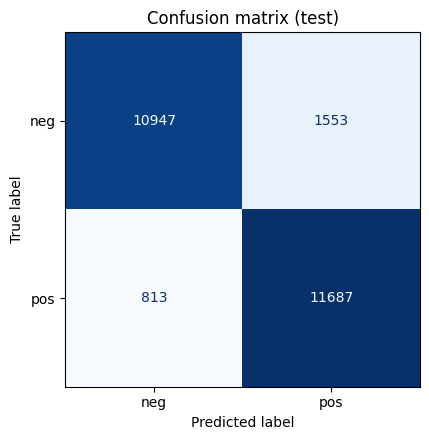

              precision    recall  f1-score   support

         neg     0.9309    0.8758    0.9025     12500
         pos     0.8827    0.9350    0.9081     12500

    accuracy                         0.9054     25000
   macro avg     0.9068    0.9054    0.9053     25000
weighted avg     0.9068    0.9054    0.9053     25000

neg → pos: 1553 ошибок


In [8]:
pred_out = trainer.predict(tokenized["test"])
logits = pred_out.predictions
preds = np.argmax(logits, axis=-1)
labels = pred_out.label_ids

cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=label_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(labels, preds, target_names=label_names, digits=4))

print(f"neg → pos: {cm[0, 1]} ошибок")

# **Часть 3. Анализ ошибок (краткий)**

In [9]:
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()

test_df = pd.DataFrame({
    "text": datasets["test"]["text"],
    "true": [label_names[i] for i in labels],
    "pred": [label_names[i] for i in preds],
    "confidence": probs.max(axis=1),
    "n_words": [len(t.split()) for t in datasets["test"]["text"]],
})
test_df["error"] = test_df["true"] != test_df["pred"]
test_df["text_clean"] = test_df["text"].str.replace("<br />", " ", regex=False)

print(f"Всего ошибок: {test_df['error'].sum()} из {len(test_df)} ({test_df['error'].mean()*100:.2f}%)")

test_df["length_bucket"] = pd.cut(test_df["n_words"], bins=[0, 100, 200, 300, 10_000],
                                  labels=["≤100", "101–200", "201–300", ">300"])
display(test_df.groupby("length_bucket", observed=True)["error"].agg(["mean", "sum", "count"]).round(4))

print("Средняя уверенность модели: на ошибках = %.3f, на верных = %.3f" % (
    test_df.loc[test_df.error, "confidence"].mean(),
    test_df.loc[~test_df.error, "confidence"].mean()))

Всего ошибок: 2366 из 25000 (9.46%)


,mean,sum,count
length_bucket,,,
≤100,0.0749,235,3139
101–200,0.0715,842,11783
201–300,0.0942,438,4651
>300,0.1568,851,5427


Средняя уверенность модели: на ошибках = 0.865, на верных = 0.975


In [10]:
errors = test_df[test_df["error"]].sample(n=5, random_state=42)

report_table = pd.DataFrame({
    "Текст (первые 100 символов)": errors["text_clean"].str[:100] + "...",
    "Истинный класс": errors["true"],
    "Предсказанный класс": errors["pred"],
    "Уверенность": errors["confidence"].round(3),
    "Слов в тексте": errors["n_words"],
    "Гипотеза о причине": "← заполнить",
})
pd.set_option("display.max_colwidth", 120)
display(report_table.reset_index(drop=True))

for i, (_, row) in enumerate(errors.iterrows(), 1):
    print(f"\n--- Пример {i}: истина={row['true']}, предсказано={row['pred']}, "
          f"уверенность={row['confidence']:.3f}, слов={row['n_words']} ---")
    print(row["text_clean"][:1500])

,Текст (первые 100 символов),Истинный класс,Предсказанный класс,Уверенность,Слов в тексте,Гипотеза о причине
0,Oh dear! The BBC is not about to be knocked off its pedestal for absorbing period dramas by this one...,neg,pos,0.743,179,← заполнить
1,"Having seen the full length film Kieslowski made out of this episode of ""The Decalogue"" years ago, c...",pos,neg,0.818,326,← заполнить
2,"Cheaply pieced together of recycled film footage, music and ideas, this film cannot really be called...",neg,pos,0.991,121,← заполнить
3,"Axel Nordman (Cassavetes) shows up on the New York dockyards looking for a job, but with a hidden pa...",pos,neg,0.611,392,← заполнить
4,I gave Soul Plane the benefit of the doubt and thought there would actually be something of comedic ...,neg,pos,0.591,170,← заполнить



--- Пример 1: истина=neg, предсказано=pos, уверенность=0.743, слов=179 ---
Oh dear! The BBC is not about to be knocked off its pedestal for absorbing period dramas by this one. I agree this novel of Jane Austens is the difficult to portray particularly to a modern audience, the heroine is hardly a Elizabeth Bennet, even Edmund is not calculated to cause female hearts to skip a beat. However I must say I was hoping for an improvement on the last and was sadly disappointed. The basic story was preserved, but the dialogue was so altered that all that was Jane Austen's tone, manner, feeling, wit, depth, was diluted if not lost. If some past adaptions may be seen as dated the weakness of this one must be that it is too modern ('his life is one long party'?????) The cast was generally adequate, but I think Billie Piper was the wrong choice, it needed someone more restrained, I gained no impression of hidden depths beneath a submissive exterior, she was more like a frolicking child. I see I 

**Задание на подумать. Сравните f1_macro и accuracy. Если f1_macro заметно ниже accuracy, какие классы модель путает? Выпишите 2–3 пары confused classes.**

f1_macro и accuracy совпадают или имеют минимальные различия (validation - совпадают полностью, test - отличие в 0.0001). Это может говорить о том, что классы в датасете хорошо сбалансирвоан, поэтому каждый класс вносит одинаковый вклад в обе метрики. При этом модель склонна предсказывать pos чаще, чем нужно: neg → pos 1553 ошибки против 813 у pos → neg; recall neg 0.876 против 0.935 у pos.


Основные гипотезы:
1. мешанная рецензия: автор аргкментирует, почему он считает "плохой" фильм хорошим, употребяет много "позитивных" эпитетов: amusing, enjoy, like, heroic, attraction etc (пример 3)
2. Отрицание выражается через сложные конструкции без прямого употребдения отрицательных частиц („not bad“, „can't say it was boring“), что путает модель.
3. Отзыв пересказывает сюжет с негативной лексикой (смерть, насилие), а оценка автора положительная. (пример 2)
4. Ошибка в разметке: оценка автора не совпадает с текстом, ошибка скорее в метке. (пример 3)

# **Часть 4**

**Вопрос для размышления. В текстовой классификации вы передаёте в модель input_ids и attention_mask. В мультимодальной модели с изображением и текстом — что добавляется? Как вы думаете, почему Processor (а не Tokenizer) отвечает за подготовку входов?**

**Что добавляется.** pixel_values: тензор изображения после ресайза, нормализации и приведения к формату модели. В зависимости от модели добавляются и служебные поля: image_grid_thw, image_sizes, pixel_attention_mask, при нарезке изображения на тайлы количество тайлов и т. п. attention_mask остаётся, но теперь покрывает и визуальные позиции.

Используется именно proccessor, так как он в отличие от tokenizer способен обрабатывать и изображения в том числе (ImageProcessor, FeatureExtractor, AutoProcessor).